In [1]:
%pip install -q pandas numpy scipy matplotlib seaborn statsmodels


In [2]:
import sys
import numpy as np
import pandas as pd
import scipy
import matplotlib
import seaborn as sns
import statsmodels

print("Python:", sys.version.split()[0])
print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("SciPy:", scipy.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Seaborn:", sns.__version__)
print("statsmodels:", statsmodels.__version__)


Python: 3.13.18
NumPy: 2.1.3
pandas: 2.2.3
SciPy: 1.16.3
Matplotlib: 3.10.0
Seaborn: 0.13.2
statsmodels: 0.15.0


In [3]:
# CELL E1 - Imports, settings, and load ONE split from the bucket (df always follows SPLIT_FILE)
import numpy as np
import pandas as pd

BUCKET = "mortgage_irish_forecast_trends"
SPLIT_FILE = "train"            # EDA decisions use "train" only; change it, then re-run E1 and E2
FILE_FORMAT = "parquet"         # must match the format the pipeline exported ("parquet" or "csv")
opts = {"token": "anon"}        # anonymous read needs a public bucket; otherwise authenticate and use opts = {}

def load_split(name):
    """Read one split file from gs://<bucket>/sharded/ and parse the date column."""
    url = f"gs://{BUCKET}/sharded/{name}.{FILE_FORMAT}"
    d = (pd.read_parquet(url, storage_options=opts) if FILE_FORMAT == "parquet"
         else pd.read_csv(url, storage_options=opts))
    d["reporting_date"] = pd.to_datetime(d["reporting_date"])
    return d

DATA_URL = f"gs://{BUCKET}/sharded/{SPLIT_FILE}.{FILE_FORMAT}"
if SPLIT_FILE != "train":
    print(f"NOTE: loading '{SPLIT_FILE}'. Use it for description or validation only - base EDA decisions on train.")

df = load_split(SPLIT_FILE)
print(f"Loaded {DATA_URL}")
print(f"Rows: {df.shape[0]:,}; columns: {df.shape[1]}; split labels: {df['split'].value_counts().to_dict()}")
display(df.head())

Loaded gs://mortgage_irish_forecast_trends/sharded/train.parquet
Rows: 71; columns: 15; split labels: {'train': 71}


,reporting_date,entity_group,loan_format,arrears_total,over180_share,b91_180_growth,target_next_q,arrears_total_lag1,arrears_total_lag2,arrears_total_lag3,arrears_total_lag4,data_vintage,feature_version,target_quarter,split
0,2010-09-30,All,PDH,86362.0,0.324784,0.067176,89234.0,82377.0,76100.0,69647.0,63619.0,2026-09-30,v1,2010Q4,train
1,2010-12-31,All,PDH,89234.0,0.351189,0.060130,94518.0,86362.0,82377.0,76100.0,69647.0,2026-09-30,v1,2011Q1,train
2,2011-03-31,All,PDH,94518.0,0.373908,0.083371,102397.0,89234.0,86362.0,82377.0,76100.0,2026-09-30,v1,2011Q2,train
3,2011-06-30,All,PDH,102397.0,0.391027,0.101976,110597.0,94518.0,89234.0,86362.0,82377.0,2026-09-30,v1,2011Q3,train
4,2011-09-30,All,PDH,110597.0,0.419279,0.055715,118464.0,102397.0,94518.0,89234.0,86362.0,2026-09-30,v1,2011Q4,train


In [4]:
# CELL E2 - Data-contract checks (the Titanic "required / is_unique" cell, adapted)
TARGET = "arrears_total"          # "arrears_rate" if STOCK_ROW was set in the pipeline
LAGS = (1, 2, 3, 4)
SPLIT_WINDOWS = {                 # TARGET-quarter windows; must match CELL 2 of the pipeline notebook
    "train":    (None, "2020Q4"),
    "dev":      ("2021Q1", "2022Q4"),
    "test":     ("2023Q1", "2024Q4"),
    "new_data": ("2025Q1", None),
}

def check_contract(df, split):
    """Fail loudly if a split file does not match what the pipeline promised to write."""
    lag_cols = [f"{TARGET}_lag{l}" for l in LAGS]
    feature_cols = ["arrears_total", "over180_share", "b91_180_growth"] + lag_cols
    required = {"reporting_date", "entity_group", "loan_format", "target_next_q",
                "target_quarter", "split", "data_vintage", "feature_version", *feature_cols}
    assert required.issubset(df.columns), f"missing columns: {sorted(required - set(df.columns))}"

    d = df.copy()
    d["reporting_date"] = pd.to_datetime(d["reporting_date"])      # CSV files store dates as text

    # 1. keys, types and labels
    key = ["reporting_date", "entity_group", "loan_format"]
    assert not d[key].isna().any().any(), "null values in key columns"
    assert not d.duplicated(key).any(), "duplicate (quarter, entity, format) rows"
    assert set(d["loan_format"]) <= {"PDH", "BTL"}, f"unexpected loan_format: {set(d['loan_format'])}"
    assert (d["split"] == split).all(), \
        f"expected only split='{split}' but found {d['split'].value_counts().to_dict()} - wrong file loaded?"
    for c in feature_cols + ["target_next_q"]:
        assert pd.api.types.is_numeric_dtype(d[c]), f"{c} is not numeric"
    for c in ["data_vintage", "feature_version"]:
        assert d[c].nunique() == 1, f"{c} has more than one value"

    # 2. value ranges
    assert (d["arrears_total"] >= 0).all(), "negative arrears_total"
    assert d["over180_share"].between(0, 1).all(), "over180_share outside [0, 1] (check the over-180 rebuild)"
    if TARGET == "arrears_rate":
        assert d[TARGET].between(0, 1).all(), "arrears_rate outside [0, 1]"

    # 3. completeness: features always present, label missing only for the newest new_data quarter
    assert not d[feature_cols].isna().any().any(), "nulls in feature columns"
    if split == "new_data":
        unlabeled = d.loc[d["target_next_q"].isna(), "reporting_date"]
        assert (unlabeled == d["reporting_date"].max()).all(), "unlabeled rows other than the newest quarter"
    else:
        assert d["target_next_q"].notna().all(), "labels missing in a labelled split"

    # 4. label timing: target quarter must be exactly the feature quarter + 1
    expected = (pd.PeriodIndex(d["reporting_date"], freq="Q") + 1).astype(str)
    assert np.array_equal(expected.to_numpy(dtype=object), d["target_quarter"].to_numpy(dtype=object)), \
        "target_quarter is not reporting quarter + 1"

    # 5. split window: target quarters must sit inside this split's historical window
    tq = pd.PeriodIndex(d["target_quarter"], freq="Q")
    lo, hi = SPLIT_WINDOWS[split]
    if lo: assert tq.min() >= pd.Period(lo), f"{split}: target quarters start before {lo}"
    if hi: assert tq.max() <= pd.Period(hi), f"{split}: target quarters run past {hi}"

    # 6. each series: no missing quarters, label = next quarter's value, lags = past values
    for grp_key, g in d.sort_values("reporting_date").groupby(["entity_group", "loan_format"]):
        q = pd.PeriodIndex(g["reporting_date"], freq="Q").asi8
        assert (np.diff(q) == 1).all(), f"missing quarter(s) in series {grp_key}"
        cur = g[TARGET].to_numpy()
        assert np.allclose(g["target_next_q"].to_numpy()[:-1], cur[1:]), f"label != next quarter's value in {grp_key}"
        for l, col in zip(LAGS, lag_cols):
            if len(g) > l:
                assert np.allclose(g[col].to_numpy()[l:], cur[:-l]), f"{col} does not match the past in {grp_key}"

    print(f"Data contract passed for '{split}': {len(d)} rows, {d['reporting_date'].nunique()} quarters, "
          f"{d['reporting_date'].min().date()} -> {d['reporting_date'].max().date()}, "
          f"target quarters {d['target_quarter'].min()} -> {d['target_quarter'].max()}")

check_contract(df, SPLIT_FILE)

Data contract passed for 'train': 71 rows, 41 quarters, 2010-09-30 -> 2020-09-30, target quarters 2010Q4 -> 2020Q4


In [5]:
# CELL E3 - Structure and quality summary (File Content and if it is clean)
print("Shape:", df.shape, "| memory:", f"{df.memory_usage(deep=True).sum() / 1024:.1f} KB")
display(df.dtypes.astype(str).to_frame("dtype")
          .join(df.isna().sum().rename("nulls"))
          .join(df.nunique().rename("n_unique")))

const = [c for c in df.columns if df[c].nunique() == 1]
print("Constant columns (carry no information):", const)
print("Duplicate (quarter, entity, format) rows:",
      int(df.duplicated(["reporting_date", "entity_group", "loan_format"]).sum()))

# coverage per loan format, and whether any quarter is missing inside it
cov = df.groupby("loan_format")["reporting_date"].agg(first="min", last="max", n_quarters="nunique")
cov["expected"] = [len(pd.period_range(r["first"], r["last"], freq="Q")) for _, r in cov.iterrows()]
cov["missing_quarters"] = cov["expected"] - cov["n_quarters"]
display(cov)

display(df.select_dtypes("number").describe().T[["count", "mean", "std", "min", "50%", "max"]].round(3))

Shape: (71, 15) | memory: 27.5 KB


,dtype,nulls,n_unique
reporting_date,datetime64[us],0,41
entity_group,object,0,1
loan_format,object,0,2
arrears_total,float64,0,71
over180_share,float64,0,71
b91_180_growth,float64,0,71
target_next_q,float64,0,71
arrears_total_lag1,float64,0,71
arrears_total_lag2,float64,0,71
arrears_total_lag3,float64,0,71


Constant columns (carry no information): ['entity_group', 'data_vintage', 'feature_version', 'split']
Duplicate (quarter, entity, format) rows: 0


,first,last,n_quarters,expected,missing_quarters
loan_format,,,,,
BTL,2013-06-28,2020-09-30,30,30,0
PDH,2010-09-30,2020-09-30,41,41,0


,count,mean,std,min,50%,max
arrears_total,71.0,66235.099,40346.623,15797.000,65043.000,142892.000
over180_share,71.0,0.644,0.114,0.325,0.632,0.792
b91_180_growth,71.0,-0.033,0.082,-0.220,-0.033,0.340
target_next_q,71.0,65443.746,40628.349,15138.000,63437.000,142892.000
arrears_total_lag1,71.0,66946.408,40042.023,16088.000,66218.000,142892.000
arrears_total_lag2,71.0,67525.254,39722.382,16562.000,66426.000,142892.000
arrears_total_lag3,71.0,67892.465,39425.765,16562.000,66549.000,142892.000
arrears_total_lag4,71.0,68190.775,39139.263,17413.000,66549.000,142892.000


In [6]:
# CELL E4 - Plot style and derived EDA columns (Model Focus - Growth)
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "figure.figsize": (10, 4), "axes.grid": True,
                     "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})
COL = {"PDH": "#1f77b4", "BTL": "#d62728"}      # one colour per loan format in every figure
FORMATS = sorted(df["loan_format"].unique())

eda = df.sort_values(["loan_format", "reporting_date"]).copy()
eda["growth_prev"] = eda[TARGET] / eda[f"{TARGET}_lag1"] - 1       # growth observed this quarter
eda["growth_next"] = eda["target_next_q"] / eda[TARGET] - 1        # growth we will predict (the label, as a rate)
eda["change_next"] = eda["target_next_q"] - eda[TARGET]            # the same, as a change in accounts
eda["quarter_of_year"] = eda["reporting_date"].dt.quarter
print("Derived columns added:", ["growth_prev", "growth_next", "change_next", "quarter_of_year"])
display(eda[["reporting_date", "loan_format", TARGET, "growth_prev", "growth_next"]].tail(4))

Derived columns added: ['growth_prev', 'growth_next', 'change_next', 'quarter_of_year']


,reporting_date,loan_format,arrears_total,growth_prev,growth_next
64,2019-12-31,PDH,60596.0,-0.019514,0.046884
66,2020-03-31,PDH,63437.0,0.046884,-0.104750
68,2020-06-30,PDH,56792.0,-0.104750,-0.023665
70,2020-09-30,PDH,55448.0,-0.023665,-0.008332


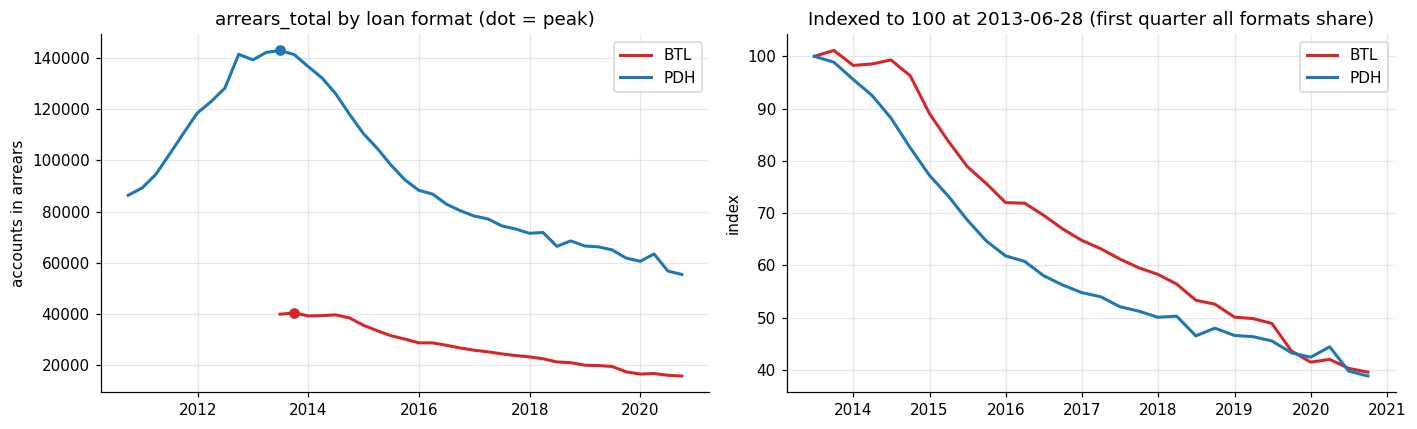

,peak_quarter,peak_value,latest_value,change_since_peak_%
loan_format,,,,
BTL,2013-09-30,40396.0,15797.0,-60.9
PDH,2013-06-28,142892.0,55448.0,-61.2


In [7]:
# CELL E5 - The main series: level, relative shape, and where each format peaked
common_start = eda.groupby("loan_format")["reporting_date"].min().max()    # first quarter ALL formats have
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for f in FORMATS:
    s = eda[eda["loan_format"] == f].set_index("reporting_date")[TARGET]
    ax[0].plot(s.index, s, color=COL[f], label=f, lw=2)
    s2 = s[s.index >= common_start]
    ax[1].plot(s2.index, 100 * s2 / s2.iloc[0], color=COL[f], label=f, lw=2)
    ax[0].scatter(s.idxmax(), s.max(), color=COL[f], zorder=3)
ax[0].set(title=f"{TARGET} by loan format (dot = peak)", ylabel="accounts in arrears")
ax[1].set(title=f"Indexed to 100 at {common_start.date()} (first quarter all formats share)", ylabel="index")
for a in ax: a.legend()
plt.tight_layout(); plt.show()

peak = (eda.loc[eda.groupby("loan_format")[TARGET].idxmax(), ["loan_format", "reporting_date", TARGET]]
        .rename(columns={"reporting_date": "peak_quarter", TARGET: "peak_value"}).set_index("loan_format"))
peak["latest_value"] = eda.groupby("loan_format")[TARGET].last()
peak["change_since_peak_%"] = (100 * (peak["latest_value"] / peak["peak_value"] - 1)).round(1)
display(peak)

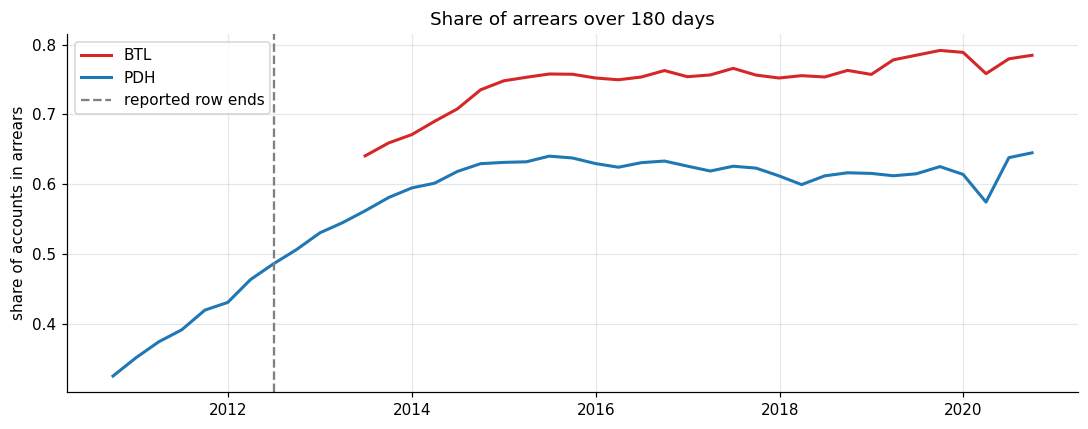

,step_at_handover,typical_quarterly_move,step_in_typical_moves
loan_format,,,
BTL,NaN,NaN,NaN
PDH,0.0203,0.0111,1.8


NaN = this format has no data on both sides of the handover in this split.


In [8]:
# CELL E6 - Checks the rebuilt over-180 measure and if the joins up smoothly where the reported row ends
HANDOVER = pd.Timestamp("2012-06-29")     # last quarter that had the reported over-180 row

fig, ax = plt.subplots(figsize=(10, 4))
for f in FORMATS:
    s = eda[eda["loan_format"] == f].set_index("reporting_date")["over180_share"]
    ax.plot(s.index, s, color=COL[f], label=f, lw=2)
ax.axvline(HANDOVER, color="grey", ls="--", label="reported row ends")
ax.set(title="Share of arrears over 180 days", ylabel="share of accounts in arrears"); ax.legend()
plt.tight_layout(); plt.show()

rows = []
for f in FORMATS:
    s = eda[eda["loan_format"] == f].set_index("reporting_date")["over180_share"]
    before, after = s[s.index <= HANDOVER], s[s.index > HANDOVER]
    if len(before) < 2 or len(after) < 2:
        rows.append((f, None, None, None)); continue
    step = after.iloc[0] - before.iloc[-1]                     # change across the handover
    typical = s.diff().abs().median()                          # a normal quarter-to-quarter move
    rows.append((f, round(step, 4), round(typical, 4), round(step / typical, 1) if typical else None))
display(pd.DataFrame(rows, columns=["loan_format", "step_at_handover", "typical_quarterly_move", "step_in_typical_moves"])
          .set_index("loan_format"))
print("NaN = this format has no data on both sides of the handover in this split.")

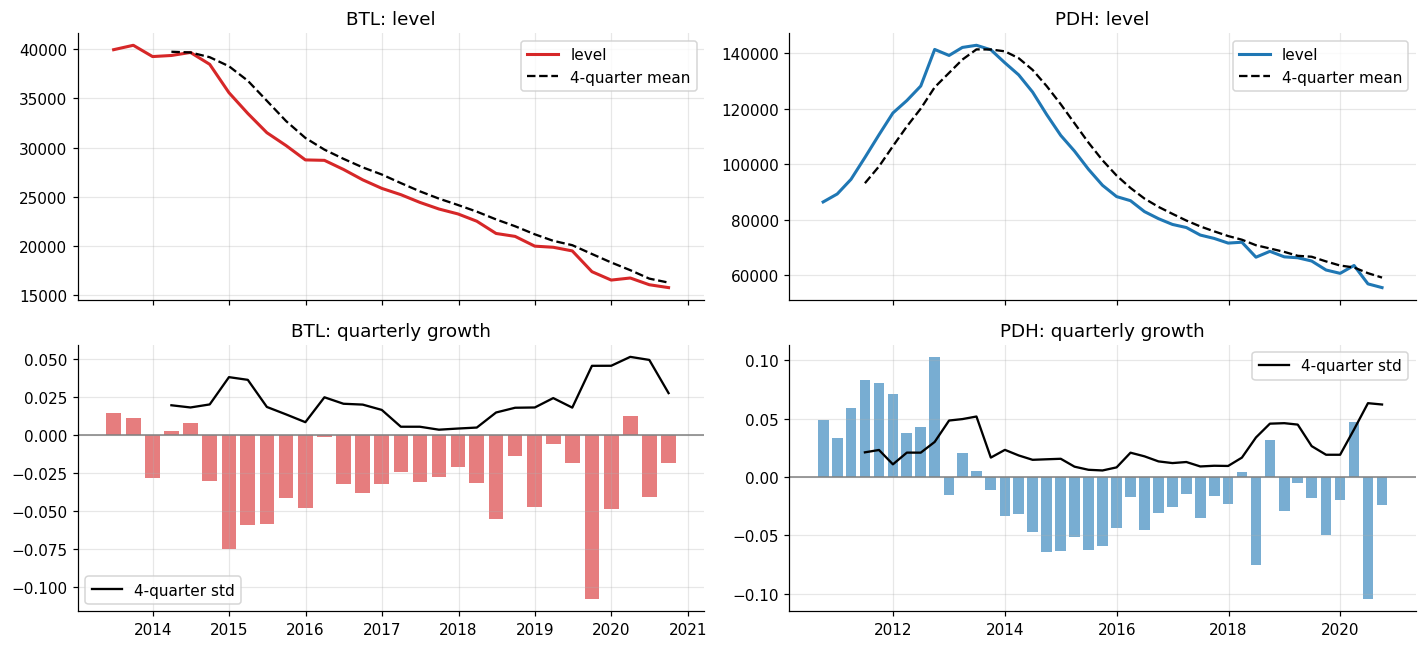

,mean_1st_half,mean_2nd_half,std_1st_half,std_2nd_half
loan_format,,,,
BTL,-0.0272,-0.0320,0.0282,0.0274
PDH,0.0102,-0.0263,0.0548,0.0328


ADF BTL level  p-value = 0.777   (small p suggests stationary)
ADF BTL growth p-value = 0.000   (small p suggests stationary)
ADF PDH level  p-value = 0.958   (small p suggests stationary)
ADF PDH growth p-value = 0.000   (small p suggests stationary)


In [9]:
# CELL E7 - Level vs growth: is the series stationary, and is variability stable?
fig, ax = plt.subplots(2, 2, figsize=(13, 6), sharex="col")
for i, f in enumerate(FORMATS):
    d = eda[eda["loan_format"] == f].set_index("reporting_date")
    ax[0, i].plot(d.index, d[TARGET], color=COL[f], lw=2, label="level")
    ax[0, i].plot(d.index, d[TARGET].rolling(4).mean(), color="black", ls="--", label="4-quarter mean")
    ax[0, i].set_title(f"{f}: level"); ax[0, i].legend()
    ax[1, i].bar(d.index, d["growth_prev"], width=70, color=COL[f], alpha=0.6)
    ax[1, i].plot(d.index, d["growth_prev"].rolling(4).std(), color="black", label="4-quarter std")
    ax[1, i].axhline(0, color="grey", lw=1); ax[1, i].set_title(f"{f}: quarterly growth"); ax[1, i].legend()
plt.tight_layout(); plt.show()

# does the mean or spread of growth change between the first and second half of the sample?
rows = []
for f in FORMATS:
    g = eda[eda["loan_format"] == f]["growth_prev"].dropna()
    h = len(g) // 2
    rows.append((f, g.iloc[:h].mean(), g.iloc[h:].mean(), g.iloc[:h].std(), g.iloc[h:].std()))
display(pd.DataFrame(rows, columns=["loan_format", "mean_1st_half", "mean_2nd_half", "std_1st_half", "std_2nd_half"])
          .set_index("loan_format").round(4))

try:   # formal check if statsmodels is installed (it is in Colab)
    import warnings
    warnings.simplefilter("ignore", FutureWarning)
    from statsmodels.tsa.stattools import adfuller
    for f in FORMATS:
        for name, s in [("level", eda[eda.loan_format == f][TARGET]), ("growth", eda[eda.loan_format == f]["growth_prev"].dropna())]:
            print(f"ADF {f:3s} {name:6s} p-value = {adfuller(s)[1]:.3f}   (small p suggests stationary)")
except ImportError:
    print("statsmodels not installed - rely on the table and plots above.")

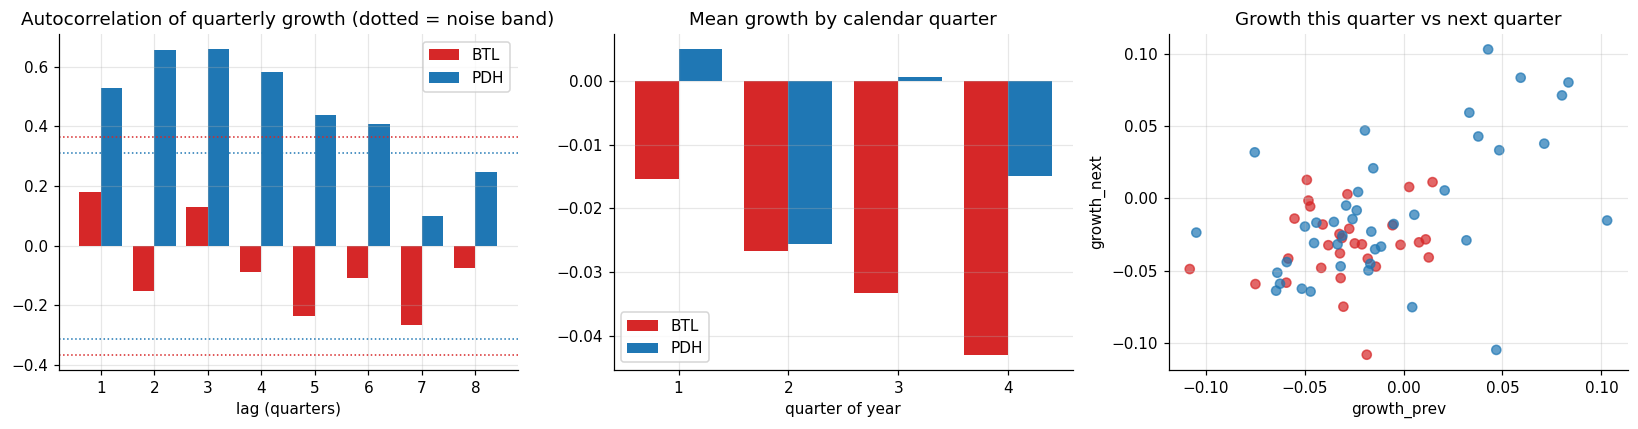

In [10]:
# CELL E8 - Memory and seasonality: how many lags matter, and is there a quarterly pattern?
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for f in FORMATS:
    g = eda[eda["loan_format"] == f]["growth_prev"].dropna().reset_index(drop=True)
    acf = [g.autocorr(lag=k) for k in range(1, 9)]
    off = 0.2 if f == FORMATS[-1] else -0.2
    ax[0].bar(np.arange(1, 9) + off, acf, width=0.4, color=COL[f], label=f)
    ax[0].axhline(2 / np.sqrt(len(g)), color=COL[f], ls=":", lw=1)       # rough 95% noise band
    ax[0].axhline(-2 / np.sqrt(len(g)), color=COL[f], ls=":", lw=1)
    seas = eda[eda["loan_format"] == f].groupby("quarter_of_year")["growth_prev"].mean()
    ax[1].bar(seas.index + off, seas.values, width=0.4, color=COL[f], label=f)
ax[0].set(title="Autocorrelation of quarterly growth (dotted = noise band)", xlabel="lag (quarters)", xticks=range(1, 9))
ax[1].set(title="Mean growth by calendar quarter", xlabel="quarter of year", xticks=[1, 2, 3, 4])
ax[2].scatter(eda["growth_prev"], eda["growth_next"], c=eda["loan_format"].map(COL), alpha=0.7)
ax[2].set(title="Growth this quarter vs next quarter", xlabel="growth_prev", ylabel="growth_next")
for a in ax[:2]: a.legend()
plt.tight_layout(); plt.show()

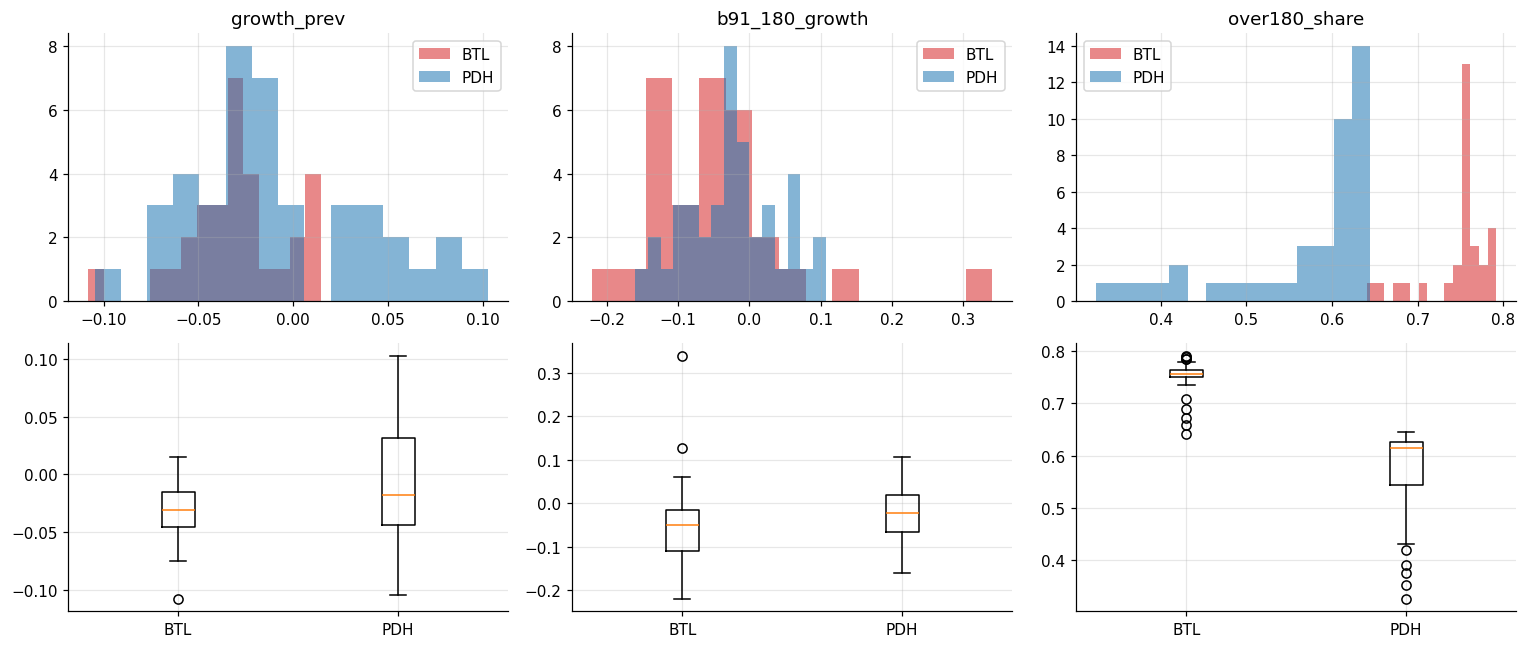

17 flagged values. Look up each quarter: real event, data artefact, or just a long tail?


,loan_format,column,quarter,value
0,BTL,growth_prev,2019-09-30,-0.1081
1,BTL,b91_180_growth,2019-06-28,0.1272
2,BTL,b91_180_growth,2020-06-30,0.3404
3,BTL,over180_share,2013-06-28,0.6405
4,BTL,over180_share,2013-09-30,0.6591
5,BTL,over180_share,2013-12-31,0.6711
6,BTL,over180_share,2014-03-31,0.6900
7,BTL,over180_share,2014-06-30,0.7079
8,BTL,over180_share,2019-06-28,0.7849
9,BTL,over180_share,2019-09-30,0.7917


In [11]:
# CELL E9 - Distributions and outliers (flagged with the 1.5 x IQR rule, not removed)
cols = ["growth_prev", "b91_180_growth", "over180_share"]
fig, ax = plt.subplots(2, 3, figsize=(14, 6))
for j, c in enumerate(cols):
    for f in FORMATS:
        ax[0, j].hist(eda.loc[eda.loan_format == f, c].dropna(), bins=15, alpha=0.55, color=COL[f], label=f)
    ax[0, j].set_title(c); ax[0, j].legend()
    ax[1, j].boxplot([eda.loc[eda.loan_format == f, c].dropna() for f in FORMATS])
    ax[1, j].set_xticklabels(FORMATS)
plt.tight_layout(); plt.show()

flags = []
for f in FORMATS:
    for c in cols:
        s = eda[eda["loan_format"] == f].set_index("reporting_date")[c].dropna()
        q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
        for d, v in s[(s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)].items():
            flags.append((f, c, d.date(), round(v, 4)))
flag_df = pd.DataFrame(flags, columns=["loan_format", "column", "quarter", "value"])
print(f"{len(flag_df)} flagged values. Look up each quarter: real event, data artefact, or just a long tail?")
display(flag_df)

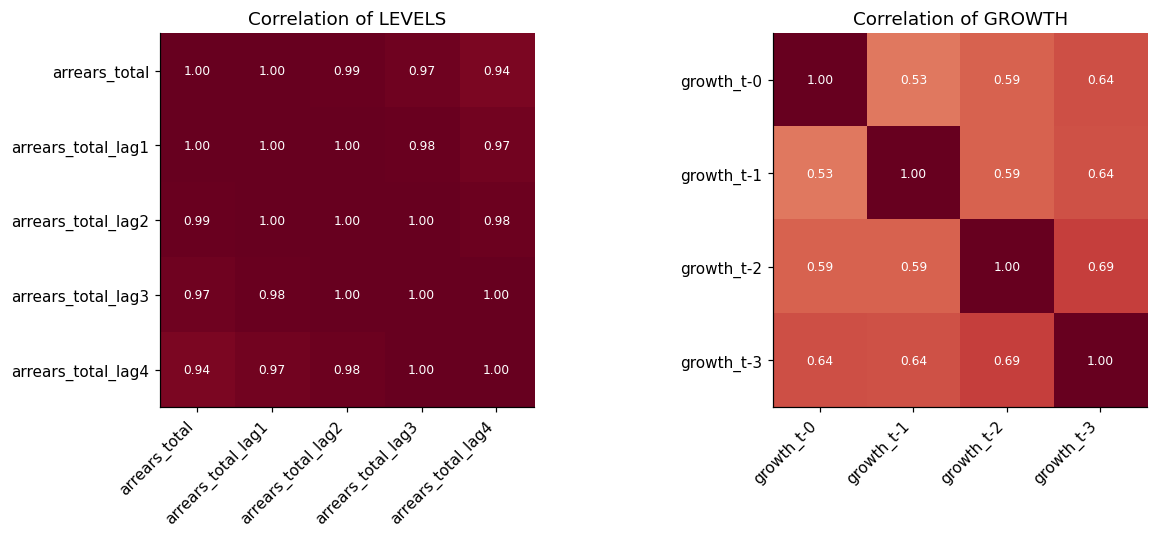

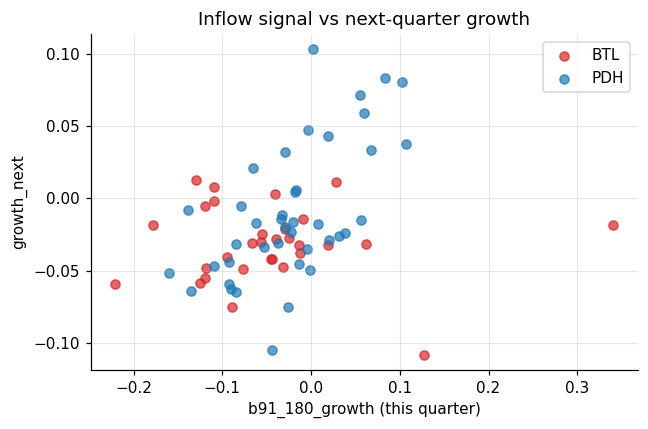

,"corr(b91_180_growth, growth_next)","corr(growth_prev, growth_next)"
loan_format,,
BTL,-0.045,0.174
PDH,0.618,0.528


In [12]:
# CELL E10 - Relationships: why levels mislead, and does the inflow signal lead growth?
lv = [TARGET] + [f"{TARGET}_lag{l}" for l in LAGS]
sub = eda.copy()
for k in range(4):     # growth k quarters ago, rebuilt from the level and lag columns
    sub[f"growth_t-{k}"] = sub[lv[k]] / sub[lv[k + 1]] - 1
gr = [f"growth_t-{k}" for k in range(4)]

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for a, cols_, title in [(ax[0], lv, "Correlation of LEVELS"), (ax[1], gr, "Correlation of GROWTH")]:
    m = sub[cols_].corr()
    im = a.imshow(m, vmin=-1, vmax=1, cmap="RdBu_r")
    a.set_xticks(range(len(cols_))); a.set_yticks(range(len(cols_)))
    a.set_xticklabels(cols_, rotation=45, ha="right"); a.set_yticklabels(cols_); a.set_title(title); a.grid(False)
    for i in range(len(cols_)):
        for j in range(len(cols_)):
            a.text(j, i, f"{m.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8,
                   color="white" if abs(m.iloc[i, j]) > 0.5 else "black")
plt.tight_layout(); plt.show()

# early-warning question: does this quarter's 91-180 day inflow relate to NEXT quarter's growth?
fig, ax = plt.subplots(figsize=(6, 4))
rows = []
for f in FORMATS:
    d = eda[eda.loan_format == f]
    ax.scatter(d["b91_180_growth"], d["growth_next"], color=COL[f], alpha=0.7, label=f)
    rows.append((f, d["b91_180_growth"].corr(d["growth_next"]), d["growth_prev"].corr(d["growth_next"])))
ax.set(xlabel="b91_180_growth (this quarter)", ylabel="growth_next", title="Inflow signal vs next-quarter growth"); ax.legend()
plt.tight_layout(); plt.show()
display(pd.DataFrame(rows, columns=["loan_format", "corr(b91_180_growth, growth_next)",
                                    "corr(growth_prev, growth_next)"]).set_index("loan_format").round(3))

In [13]:
# CELL E11 - Error of the two naive forecasts on TRAIN (sets realistic targets)
rows = []
for f in FORMATS:
    d = eda[eda.loan_format == f]
    last = (d["target_next_q"] - d[TARGET]).abs().mean()                   # "next quarter = this quarter"
    seas = (d["target_next_q"] - d[f"{TARGET}_lag3"]).abs().mean()         # "next quarter = same quarter last year"
    rows.append((f, last, seas, 100 * last / d[TARGET].mean(), 100 * seas / d[TARGET].mean(), seas / last))
display(pd.DataFrame(rows, columns=["loan_format", "MAE_last_value", "MAE_seasonal_naive",
                                    "last_value_%_of_mean_level", "seasonal_%_of_mean_level",
                                    "seasonal / last_value"]).set_index("loan_format").round(2))
print("If last-value is already within a few % of the level, beating it will be hard and gains will be small.")

,MAE_last_value,MAE_seasonal_naive,last_value_%_of_mean_level,seasonal_%_of_mean_level,seasonal / last_value
loan_format,,,,,
BTL,898.87,3343.40,3.33,12.39,3.72
PDH,3885.32,14295.05,4.09,15.05,3.68


If last-value is already within a few % of the level, beating it will be hard and gains will be small.


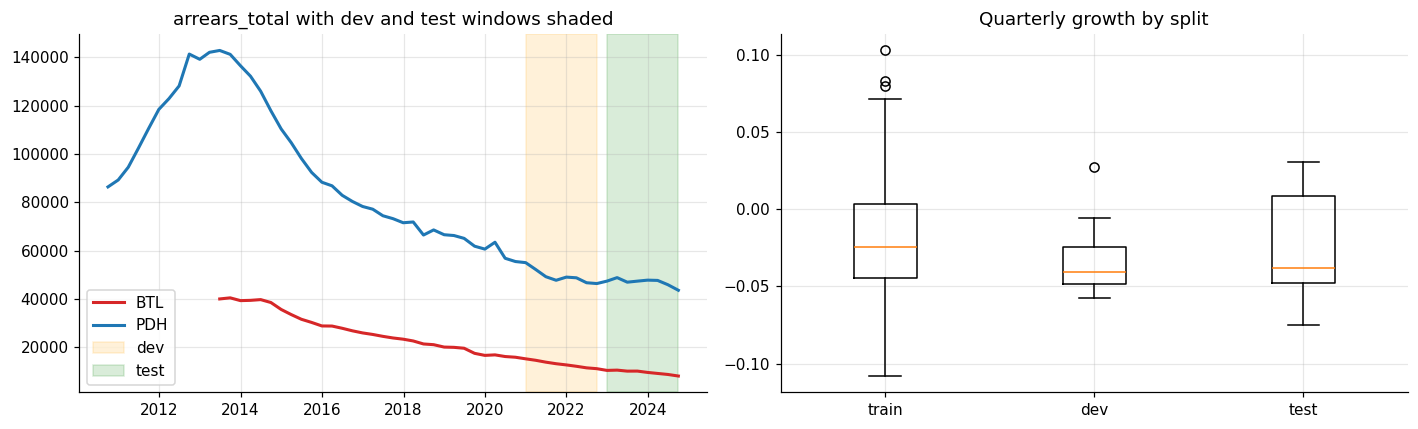

n  mean_level  mean_growth  std_growth
split loan_format                                         
dev   BTL           8  12956.5000      -0.0436      0.0079
      PDH           8  49331.2500      -0.0219      0.0285
test  BTL           8   9519.0000      -0.0390      0.0303
      PDH           8  46882.5000      -0.0073      0.0306
train BTL          30  26979.0000      -0.0296      0.0274
      PDH          41  94959.0732      -0.0085      0.0480

In [14]:
# CELL E12 - Do train, dev and test look alike? (descriptive only - never tune on dev/test)
def load_split(name):
    url = f"gs://{BUCKET}/sharded/{name}.{FILE_FORMAT}"
    d = (pd.read_parquet(url, storage_options=opts) if FILE_FORMAT == "parquet"
         else pd.read_csv(url, storage_options=opts))
    d["reporting_date"] = pd.to_datetime(d["reporting_date"])
    return d

parts = {"train": df}
for name in ["dev", "test"]:                  # new_data is deliberately NOT loaded
    parts[name] = load_split(name)
allp = pd.concat([p.assign(split=n) for n, p in parts.items()])
allp["growth_prev"] = allp[TARGET] / allp[f"{TARGET}_lag1"] - 1

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for f in FORMATS:
    d = allp[allp.loan_format == f].sort_values("reporting_date")
    ax[0].plot(d["reporting_date"], d[TARGET], color=COL[f], label=f, lw=2)
for n, c in [("dev", "orange"), ("test", "green")]:
    ax[0].axvspan(parts[n]["reporting_date"].min(), parts[n]["reporting_date"].max(), color=c, alpha=0.15, label=n)
ax[0].set(title=f"{TARGET} with dev and test windows shaded"); ax[0].legend()
data = [allp[(allp.split == n)]["growth_prev"].dropna() for n in parts]
ax[1].boxplot(data); ax[1].set_xticklabels(list(parts)); ax[1].set(title="Quarterly growth by split")
plt.tight_layout(); plt.show()

display(allp.groupby(["split", "loan_format"])
            .agg(n=("growth_prev", "size"), mean_level=(TARGET, "mean"),
                 mean_growth=("growth_prev", "mean"), std_growth=("growth_prev", "std")).round(4))